# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [3]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


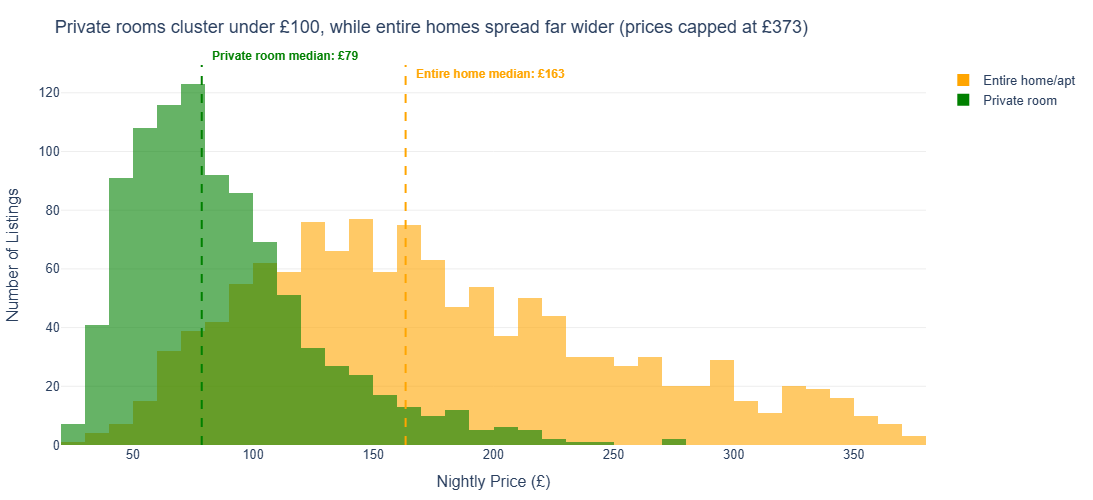

In [19]:
# Task 1
p95 = df['price'].quantile(0.95)
df_cap = df.loc[df['price'] <= p95].copy()

df_two = df_cap.loc[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])].copy()

fig = px.histogram(
    data_frame=df_two, 
    x='price',
    color='room_type',                     
    barmode='overlay',
    opacity=0.6,
    nbins=50,                             
    color_discrete_map={'Entire home/apt': 'orange', 'Private room': 'green'},
    labels={'price': 'Nightly Price (£)', 'count': 'Number of Listings', 'room_type': ''},
    height=500
)

median_entire = df_two.loc[df_two['room_type'] == 'Entire home/apt', 'price'].median()
median_private = df_two.loc[df_two['room_type'] == 'Private room', 'price'].median()

fig.add_vline(x=median_entire, line_dash='dash', line_color='orange', line_width=2,
              annotation=dict(
                  text=f'<b>Entire home median: £{median_entire:.0f}',
                  font=dict(color='orange', size=12),
                  xanchor='left',
                  yanchor='top',
                  xshift=8,  
              ))

fig.add_vline(x=median_private, line_dash='dash', line_color='green', line_width=2,
              annotation=dict(
                  text=f'<b>Private room median: £{median_private:.0f}',
                  font=dict(color='green', size=12),
                  xanchor='left',
                  yanchor='bottom',
                  xshift=8,  
              ))

fig.update_layout(
    title=f'Private rooms cluster under £100, while entire homes spread far wider (prices capped at £{p95:.0f})',
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of Listings'),
    xaxis=dict(showgrid=False),
    margin=dict(l=60, r=40, t=65, b=40)
)
fig.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

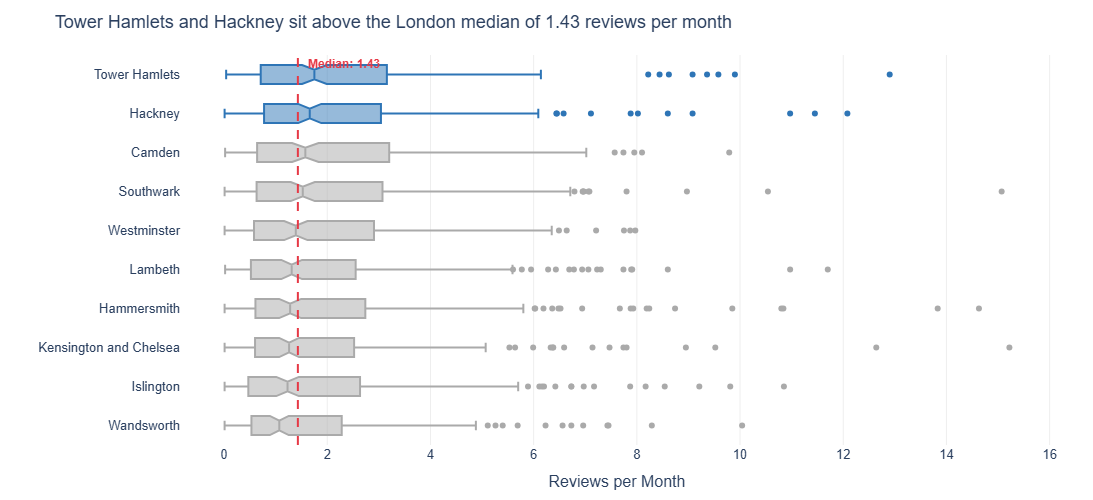

In [17]:
# Task 2

active = df.loc[df['reviews_per_month'] > 0].copy()

med_order = active.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False).index.tolist()

busiest = med_order[:2]

fig = px.box(
    data_frame=active, 
    y='neighbourhood', x='reviews_per_month',
    color='neighbourhood',
    color_discrete_map={n: ('#2E75B6' if n in busiest else '#AAAAAA') for n in med_order},
    notched=True,                  
    points='outliers',             
    labels={'reviews_per_month': 'Reviews per Month', 'neighbourhood': ''},
    category_orders={'neighbourhood': med_order}, height=500
)

median_reviews = active['reviews_per_month'].median()

fig.add_vline(x=median_reviews, line_dash='dash', line_color='#E63946', line_width=2,
              annotation=dict(
                  text=f'<b>Median: {median_reviews:.2f}',
                  font=dict(color='#E63946', size=12),
                  xanchor='left',
                  yanchor='top',
                  xshift=8,
              ))

fig.update_layout(
    title='Tower Hamlets and Hackney sit above the London median of 1.43 reviews per month',
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE', title='Reviews per Month'),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(l=60, r=40, t=55, b=40)
)
fig.show()